In [1]:
import os
# os.environ['CUDA_VISIBLE_DEVICES'] = '2'

import torch
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt

from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader 
from torch.optim import Adam
import torchvision
import torchvision.models as models
from torchsummary import summary

torch.manual_seed(1)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Data

In [2]:
batch_size = 16
train_transform = transforms.Compose(
    [
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize([0.4914, 0.4822, 0.4465], 
                             [0.2470, 0.2435, 0.2616]),
    ])

val_transform = transforms.Compose(
    [
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize([0.4914, 0.4822, 0.4465], 
                             [0.2470, 0.2435, 0.2616])
    ])

train_set = CIFAR10(
    root='./data', 
    train=True,
    download=True, 
    transform=train_transform
)

val_set = CIFAR10(
    root='./data', 
    train=False,
    download=True, 
    transform=val_transform
)

trainloader = DataLoader(
    train_set, 
    batch_size=batch_size,
    shuffle=True,
    num_workers=4,
)

testloader = DataLoader(
    val_set, 
    batch_size=batch_size,
    shuffle=False, 
    num_workers=4,
)

## Model

In [3]:
import timm

model = timm.create_model("convnext_tiny", pretrained=True)
model.head.fc = nn.Linear(in_features=768, out_features=10)

/home/nico/workspace/code/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
model = model.to(device)

In [5]:
summary(model, (3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 56, 56]           4,704
       LayerNorm2d-2           [-1, 96, 56, 56]             192
          Identity-3           [-1, 96, 56, 56]               0
            Conv2d-4           [-1, 96, 56, 56]           4,800
         LayerNorm-5           [-1, 56, 56, 96]             192
            Linear-6          [-1, 56, 56, 384]          37,248
              GELU-7          [-1, 56, 56, 384]               0
           Dropout-8          [-1, 56, 56, 384]               0
          Identity-9          [-1, 56, 56, 384]               0
           Linear-10           [-1, 56, 56, 96]          36,960
          Dropout-11           [-1, 56, 56, 96]               0
              Mlp-12           [-1, 56, 56, 96]               0
         Identity-13           [-1, 96, 56, 56]               0
         Identity-14           [-1, 96,

# Train

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=1e-4)  

In [7]:
# Function to compute loss and accuracy for test set
def evaluate(model, testloader, criterion):
    model.eval()
    test_loss = 0.0
    running_correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in testloader:
            # Move inputs and labels to the device
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
            
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            running_correct += (predicted == labels).sum().item()

    accuracy = 100 * running_correct / total
    test_loss = test_loss / len(testloader)
    return test_loss, accuracy

In [8]:
# some parameter
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []
max_epoch = 5

In [9]:
# train
for epoch in range(max_epoch):
    model.train()
    running_loss = 0.0
    running_correct = 0   # to track number of correct predictions
    total = 0             # to track total number of samples

    for i, (inputs, labels) in enumerate(trainloader, 0):
        # Move inputs and labels to the device
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        # Backward pass and optimization
        loss.backward()
        optimizer.step()  
    
        # Determine class predictions and track accuracy
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        running_correct += (predicted == labels).sum().item()


    epoch_accuracy = 100 * running_correct / total
    epoch_loss = running_loss / (i + 1)
    
    test_loss, test_accuracy = evaluate(model, testloader, criterion)
    print(f"Epoch [{(epoch + 1):3}/{max_epoch:3}] \t Loss: {epoch_loss:<11.5f} Accuracy: {epoch_accuracy:.2f}% \t Test Loss: {test_loss:<11.5f} Test Accuracy: {test_accuracy:.2f}%")
    
    # save for plot
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [  1/  5] 	 Loss: 0.25770     Accuracy: 91.60% 	 Test Loss: 0.20210     Test Accuracy: 93.35%


Epoch [  2/  5] 	 Loss: 0.14139     Accuracy: 95.26% 	 Test Loss: 0.18993     Test Accuracy: 93.94%


Epoch [  3/  5] 	 Loss: 0.09962     Accuracy: 96.64% 	 Test Loss: 0.16471     Test Accuracy: 94.87%


Epoch [  4/  5] 	 Loss: 0.07622     Accuracy: 97.51% 	 Test Loss: 0.16487     Test Accuracy: 94.73%


Epoch [  5/  5] 	 Loss: 0.05991     Accuracy: 98.03% 	 Test Loss: 0.18078     Test Accuracy: 94.61%


In [10]:
# the best accuracy
best_epoch = np.argmax(test_accuracies)
print(f"\nBest epoch: {best_epoch + 1} with test accuracy: {test_accuracies[best_epoch]:.2f}%")


Best epoch: 3 with test accuracy: 94.87%


# Plot results

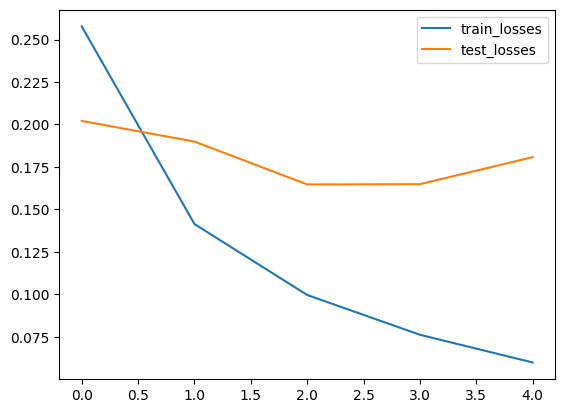

In [11]:
plt.plot(train_losses, label='train_losses')
plt.plot(test_losses, label='test_losses')
plt.legend()

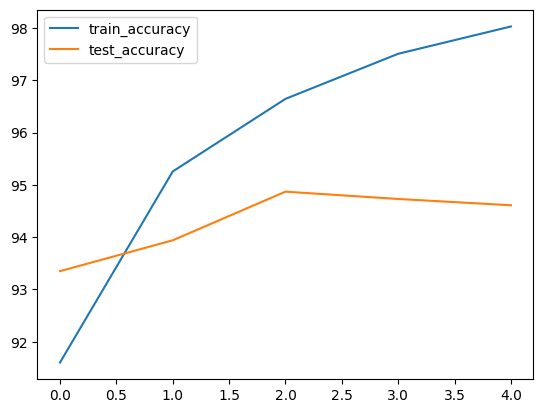

In [12]:
plt.plot(train_accuracies, label='train_accuracy')
plt.plot(test_accuracies, label='test_accuracy')
plt.legend()

In [13]:
# Save training results to JSON
import json
from datetime import datetime

results = {
    'model_name': 'ConvNeXT_tiny',
    'image_size': 224,
    'max_epoch': max_epoch,
    'train_losses': [float(x) for x in train_losses],
    'train_accuracies': [float(x) for x in train_accuracies],
    'test_losses': [float(x) for x in test_losses],
    'test_accuracies': [float(x) for x in test_accuracies],
    'best_epoch': int(np.argmax(test_accuracies)) + 1,
    'best_test_accuracy': float(max(test_accuracies)),
    'final_train_accuracy': float(train_accuracies[-1]),
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

results_file = f'ConvNeXT_tiny_size224_results.json'
with open(results_file, 'w') as f:
    json.dump(results, f, indent=2)
    
print(f"\nResults saved to {results_file}")
print(f"Best test accuracy: {results['best_test_accuracy']:.2%} at epoch {results['best_epoch']}")



Results saved to ConvNeXT_tiny_size224_results.json
Best test accuracy: 9487.00% at epoch 3
